# United States: recession probability from the yield curve, and inflation expectations

**Objective:** estimate the probability that the US is in recession in 12 months with the spread between the 10-year and the 3-month Treasury (the same idea as the model of the New York Fed), check how good the model is with ROC/AUC in sample and in real time, and compare the inflation expectations of households and markets with the real inflation.

**Data:** FRED, Federal Reserve Bank of St. Louis: `T10Y3M`, `USREC` (NBER recessions), `SAHMREALTIME`, `MICH` (University of Michigan), `T5YIE` (5-year breakeven), `CPIAUCSL`, `FEDFUNDS` and `UNRATE`.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `statsmodels` and `scikit-learn`.

## Part 1. Libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score, roc_curve

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [2]:
def fred(serie):
    s = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}", index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s = s.astype(float).dropna().resample("MS").mean()      # monthly average of the daily series
    s.index = s.index.to_period("M")
    return s.rename(serie)

series = ["T10Y3M", "USREC", "SAHMREALTIME", "MICH", "T5YIE", "CPIAUCSL", "FEDFUNDS", "UNRATE"]
df = pd.concat([fred(s) for s in series], axis=1).sort_index()
df["cpi_yoy"] = df["CPIAUCSL"].pct_change(12) * 100
df.to_csv("data/fred_monthly.csv")
df.tail()

,T10Y3M,USREC,SAHMREALTIME,MICH,T5YIE,CPIAUCSL,FEDFUNDS,UNRATE,cpi_yoy
observation_date,,,,,,,,,
2026-06,0.659524,0.0,0.07,4.6,2.365714,332.568,3.63,4.2,3.463531
2026-07,0.732727,0.0,-0.03,4.2,2.260909,332.813,3.63,4.1,3.303856
2026-08,0.807619,0.0,-0.07,4.0,2.264762,334.131,3.63,4.1,3.353016
2026-09,0.896190,0.0,0.00,NaN,2.362381,336.298,3.75,4.2,3.717251
2026-10,0.969231,NaN,NaN,NaN,2.361538,NaN,NaN,NaN,3.717251


## Part 2. Probit model

P(recession in t+12) = Phi(a + b x spread(t)). The target is the NBER indicator 12 months later.

In [3]:
df["rec_12"] = df["USREC"].shift(-12)
m = df[["T10Y3M", "rec_12"]].dropna().loc["1982-01":]
probit = sm.Probit(m["rec_12"], sm.add_constant(m["T10Y3M"])).fit(disp=False)
print(probit.summary().tables[1])
m["p"] = probit.predict()
auc = roc_auc_score(m["rec_12"], m["p"])
print("AUC in sample:", round(auc, 3))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.0226      0.108     -9.466      0.000      -1.234      -0.811
T10Y3M        -0.4434      0.080     -5.536      0.000      -0.600      -0.286
AUC in sample: 0.809


## Part 3. Real time test

The AUC in sample is optimistic because the model used all the data. In real time, at each month t we can only use the recessions that we already know (up to t-12). We estimate the model again every month since 1995.

In [4]:
pred = {}
for t in m.loc["1995-01":].index:
    tr = m.loc[:t - 12]
    pr = sm.Probit(tr["rec_12"], sm.add_constant(tr["T10Y3M"])).fit(disp=False)
    pred[t] = pr.predict(np.array([[1.0, m.loc[t, "T10Y3M"]]]))[0]
pred = pd.Series(pred)
auc_rt = roc_auc_score(m.loc[pred.index, "rec_12"], pred)
print("AUC real time since 1995:", round(auc_rt, 3))

spread = df["T10Y3M"].dropna()
p_hoy = probit.predict(np.array([[1.0, spread.iloc[-1]]]))[0]
print("Spread today:", spread.index[-1], round(spread.iloc[-1], 2), "| probability of recession in 12 months:", round(p_hoy * 100, 1), "%")

AUC real time since 1995: 0.695
Spread today: 2026-10 0.97 | probability of recession in 12 months: 7.3 %


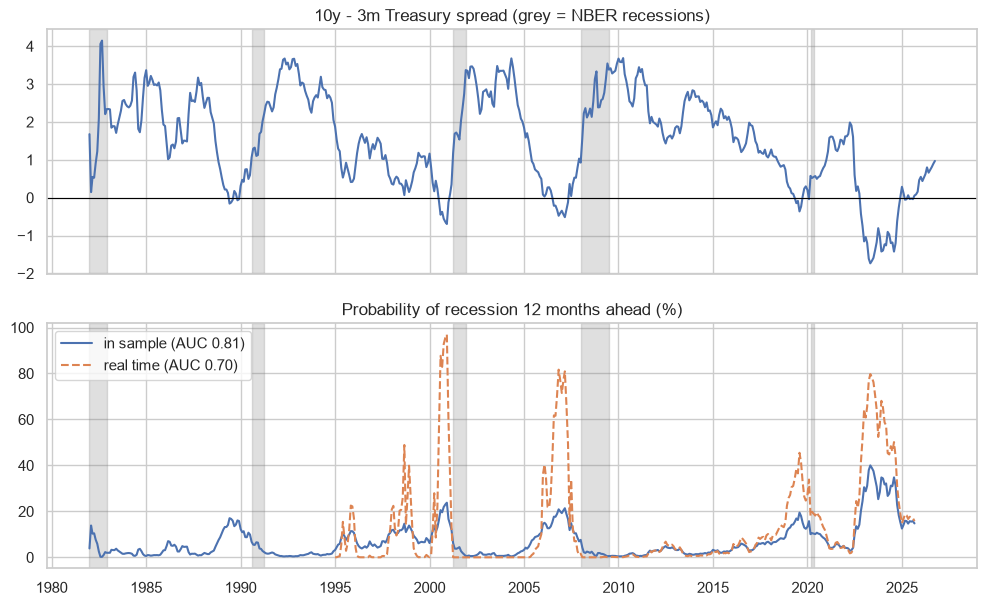

In [5]:
def sombras(ax):
    rec = df["USREC"].loc["1982":].fillna(0)
    ini = None
    for t, v in rec.items():
        if v == 1 and ini is None:
            ini = t
        if v == 0 and ini is not None:
            ax.axvspan(ini.to_timestamp(), t.to_timestamp(), color="grey", alpha=0.25)
            ini = None

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(df.loc["1982":].index.to_timestamp(), df.loc["1982":, "T10Y3M"])
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("10y - 3m Treasury spread (grey = NBER recessions)")
sombras(axes[0])
axes[1].plot(m.index.to_timestamp(), m["p"] * 100, label=f"in sample (AUC {auc:.2f})")
axes[1].plot(pred.index.to_timestamp(), pred * 100, ls="--", label=f"real time (AUC {auc_rt:.2f})")
axes[1].set_title("Probability of recession 12 months ahead (%)")
axes[1].legend()
sombras(axes[1])
plt.savefig("figures/recession_probability.png", bbox_inches="tight")
plt.show()

In [6]:
# periods with inverted curve
inv = df["T10Y3M"] < 0
inicio = inv & ~inv.shift(1, fill_value=False)
fin = inv & ~inv.shift(-1, fill_value=False)
print(pd.DataFrame({"start": inv[inicio].index, "end": inv[fin].index}).to_string())

     start      end
0  1989-06  1989-08
1  1989-11  1989-12
2  2000-07  2001-01
3  2006-08  2007-05
4  2019-05  2019-09
5  2020-02  2020-02
6  2022-11  2024-11
7  2025-03  2025-04
8  2025-06  2025-08


The inversion of November 2022 to November 2024 was the longest since 1982 and no recession came after it. This false alarm is why the AUC in real time is lower.

## Part 4. Adding the Sahm rule

In [7]:
m2 = df[["T10Y3M", "SAHMREALTIME", "rec_12"]].dropna()
probit2 = sm.Probit(m2["rec_12"], sm.add_constant(m2[["T10Y3M", "SAHMREALTIME"]])).fit(disp=False)
print("AUC spread + Sahm:", round(roc_auc_score(m2["rec_12"], probit2.predict()), 3))
print("AUC spread only, same sample:", round(roc_auc_score(m2["rec_12"], probit.predict(sm.add_constant(m2["T10Y3M"]))), 3))

AUC spread + Sahm: 0.808
AUC spread only, same sample: 0.809


The Sahm rule does not help to predict 12 months ahead: it confirms a recession when it already started, it does not anticipate it.

## Part 5. Inflation expectations: households vs markets

Who predicts better the inflation of the next 12 months: the households of the Michigan survey, the market (5-year breakeven of TIPS), or just the inflation of today?

Michigan | RMSE: 1.94
Breakeven 5y | RMSE: 1.86
Naive (CPI today) | RMSE: 2.2


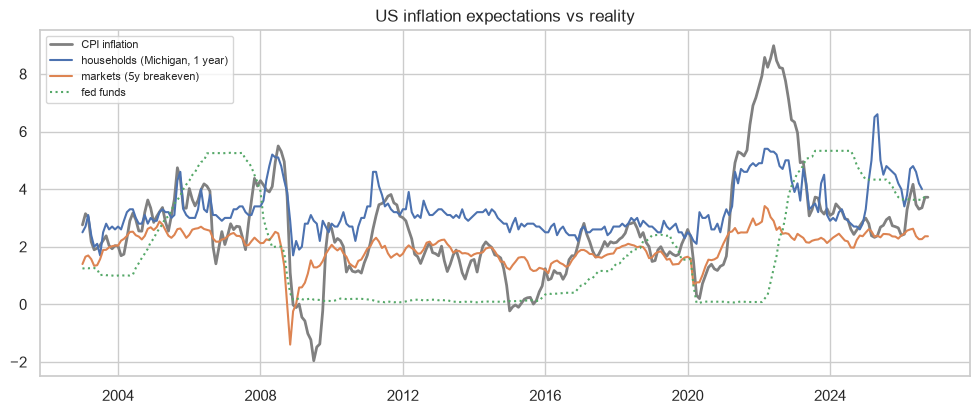

MICH        4.00
T5YIE       2.36
cpi_yoy     3.72
FEDFUNDS    3.75
UNRATE      4.20
Name: 2026-10, dtype: float64


In [8]:
c = pd.DataFrame({"Michigan": df["MICH"], "Breakeven 5y": df["T5YIE"], "Naive (CPI today)": df["cpi_yoy"],
                  "actual": df["cpi_yoy"].shift(-12)}).loc["2003-01":].dropna()
for col in ["Michigan", "Breakeven 5y", "Naive (CPI today)"]:
    print(col, "| RMSE:", round(np.sqrt(((c[col] - c["actual"]) ** 2).mean()), 2))

e = df[["MICH", "T5YIE", "cpi_yoy", "FEDFUNDS"]].loc["2003-01":]
plt.figure(figsize=(12, 4.5))
plt.plot(e.index.to_timestamp(), e["cpi_yoy"], lw=2, color="grey", label="CPI inflation")
plt.plot(e.index.to_timestamp(), e["MICH"], label="households (Michigan, 1 year)")
plt.plot(e.index.to_timestamp(), e["T5YIE"], label="markets (5y breakeven)")
plt.plot(e.index.to_timestamp(), e["FEDFUNDS"], ls=":", label="fed funds")
plt.title("US inflation expectations vs reality")
plt.legend(fontsize=8)
plt.savefig("figures/inflation_expectations.png", bbox_inches="tight")
plt.show()
print(df[["MICH", "T5YIE", "cpi_yoy", "FEDFUNDS", "UNRATE"]].ffill().iloc[-1].round(2))

## Conclusions

- With the spread at around +1 point today, the curve is not inverted anymore and the model gives a low probability of recession in 12 months (around 7%).
- The yield curve is a good signal (AUC 0.81 in sample) but in real time it is worse (around 0.70) because of the long false alarm of 2022-2024.
- Markets (breakeven) predict inflation a little better than households, and both are better than assuming that inflation will stay the same.